# Simulation with Drake
[Drake](https://drake.mit.edu) simulates multibody systems with contact. `pyctr.drake_system.ConcentricTubeRobotSystem` puts the dynamic robot model of the tutorial *Dynamics of concentric tube robots* into a Drake diagram. In the diagram the robot can:

- rotate and translate its tubes during the simulation (inputs `alphas` and `betas`),
- touch obstacles that are registered in the `SceneGraph`,
- push bodies of a `MultibodyPlant` and be mounted on one,
- be shown in Meshcat, with or without the actuation unit of the IRP robot.

The tutorial ends with the limits of the coupling.

## Robot only or robot in the actuation unit
You can simulate the tubes alone or together with a model of the [IRP actuation unit](https://github.com/IRP-TU-BS/irp_concentric_tube_continuum_robot). The robot model is the same in both cases, the unit only adds geometry to the scene.

| | Robot only | Robot in the actuation unit |
|---|---|---|
| What you see | the tubes from the base plate to the tip | housing, plates, spindles and motors; the carriages move with `betas`, the gears turn with `alphas`; the tubes come out of the tube hole |
| What you need | `pip install -e ".[drake]"` | the same, plus a copy of the irp_concentric_tube_continuum_robot repository (its `Models/stl_files`) |
| Extra code | none | `add_actuation_unit` before `plant.Finalize()`, and one `ActuationUnitCarriages` system |
| Contact | robot against obstacles | the same; the unit is drawn only, the robot does not collide with it |
| Use it when | you study the robot itself: shapes, vibrations, contact | you want to see the whole robot, check the carriage travel for a `betas` trajectory, or prepare a scene with a robot arm that carries the unit |

![Robot only](images/drake_robot_only.jpg)
![Robot in the actuation unit](images/drake_actuation_unit.jpg)

## Installation
Drake is an optional dependency of pyctr:

```bash
pip install -e ".[drake]"      # or: rye sync --features drake
```

The C++ implementation (`cpp/README.md`) computes a step of the robot about 20 times faster than Python. `ConcentricTubeRobotSystem` accepts both classes; this tutorial takes the C++ class when it is built and the Python class otherwise.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from pydrake.geometry import Box, MeshcatVisualizer, SceneGraph, StartMeshcat
from pydrake.math import RigidTransform
from pydrake.multibody.plant import AddMultibodyPlantSceneGraph, CoulombFriction
from pydrake.multibody.tree import PrismaticJoint, PrismaticSpring, SpatialInertia
from pydrake.systems.analysis import Simulator
from pydrake.systems.framework import DiagramBuilder
from pydrake.systems.primitives import TrajectorySource
from pydrake.trajectories import PiecewisePolynomial

from pyctr.drake_system import ConcentricTubeRobotSystem
from pyctr.yaml_to_model import load_continous_ctcr_model

try:
    from pyctr_cpp import DynamicConcentricTubeRobot
except ImportError:
    from pyctr.cosserat_rod_dynamics import DynamicConcentricTubeRobot
print(DynamicConcentricTubeRobot.__module__)
%matplotlib inline

pyctr_cpp._robot_dynamics


Meshcat runs a small web server. Open the printed address in a browser to watch the simulations of this tutorial; the robot is small, so zoom in with the mouse wheel.

In [2]:
meshcat = StartMeshcat()

INFO:drake:Meshcat listening for connections at http://localhost:7000


## Robot only
We load the example robot and compute its rest shape. `init_static` fixes the number of nodes, the time step is 2 ms.

In [3]:
CONFIG = "../../example_robots/ctr_robot.yaml"
robot = load_continous_ctcr_model(CONFIG, DynamicConcentricTubeRobot, dt=2e-3)
robot.init_static();

The diagram has three parts: a `SceneGraph` for the geometry, the robot system, and a `TrajectorySource` for the tube angles. The outer tube turns by 90° within 0.25 s. The robot system sends the poses of its capsules to the `SceneGraph`, which draws them in Meshcat.

Inputs are sampled at the beginning of each time step. Ports that are not connected keep the values that the robot had when the system was created.

In [4]:
builder = DiagramBuilder()
scene_graph = builder.AddSystem(SceneGraph())
ctr = builder.AddSystem(ConcentricTubeRobotSystem(robot, scene_graph))
builder.Connect(ctr.GetOutputPort("geometry_pose"), scene_graph.get_source_pose_port(ctr.source_id))
turn = PiecewisePolynomial.FirstOrderHold([0, 0.25, 1.0], [[0, 0, 0], [0, np.pi / 2, np.pi / 2]])
alphas = builder.AddSystem(TrajectorySource(turn))
builder.Connect(alphas.get_output_port(), ctr.GetInputPort("alphas"))
meshcat.Delete()
MeshcatVisualizer.AddToBuilder(builder, scene_graph, meshcat)
diagram = builder.Build()

We step the simulator and read the `positions` output (all nodes of the backbone) after each step.

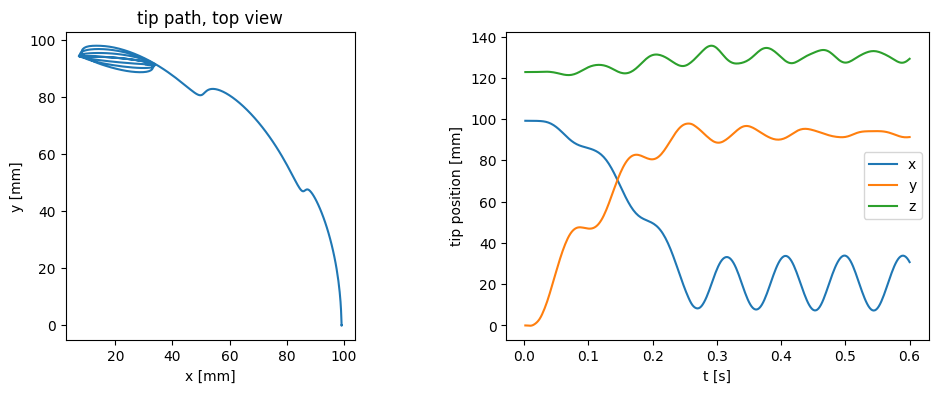

In [5]:
def simulate(diagram, system, duration, dt):
    simulator = Simulator(diagram)
    tips, times = [], np.arange(1, int(duration / dt) + 1) * dt
    for t in times:
        simulator.AdvanceTo(t - dt / 2)  # the update at t - dt gives the state at t
        context = system.GetMyContextFromRoot(simulator.get_context())
        tips.append(system.GetOutputPort("positions").Eval(context).reshape(-1, 3)[-1])
    return times, np.array(tips), simulator


times, tips, _ = simulate(diagram, ctr, 0.6, robot.dt)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(tips[:, 0] * 1e3, tips[:, 1] * 1e3)
ax1.set_xlabel("x [mm]")
ax1.set_ylabel("y [mm]")
ax1.set_aspect("equal")
ax1.set_title("tip path, top view")
for j, name in enumerate("xyz"):
    ax2.plot(times, tips[:, j] * 1e3, label=name)
ax2.set_xlabel("t [s]")
ax2.set_ylabel("tip position [mm]")
ax2.legend()
plt.show()

The tip follows the rotation with a delay and then vibrates around its new rest position. The model has no damping, only the small numerical damping of the time discretization.

## Contact and bodies of a MultibodyPlant
Obstacles are geometries with a proximity role. Here they belong to a `MultibodyPlant`, which also carries the robot: the base plate sits on a carriage that slides along y on a spring. A free box of 5 g floats in the path of the tip (no gravity).

Three rules apply:

- Create the robot system after the obstacles exist and after `plant.Finalize()`. The system checks this and raises an error otherwise.
- The robot geometry is excluded from all automatic contact queries, so the plant never sees it. The robot system computes its contacts itself.
- The output `applied_spatial_force` carries the reaction of the robot to the carriage and the contact forces to the box.

In [6]:
robot = load_continous_ctcr_model(CONFIG, DynamicConcentricTubeRobot, dt=2e-3)
robot.init_static()

builder = DiagramBuilder()
plant, scene_graph = AddMultibodyPlantSceneGraph(builder, time_step=robot.dt)
plant.mutable_gravity_field().set_gravity_vector([0, 0, 0])
carriage = plant.AddRigidBody("carriage", SpatialInertia.SolidBoxWithMass(0.2, 0.04, 0.04, 0.02))
slider = plant.AddJoint(PrismaticJoint("slider", plant.world_frame(), carriage.body_frame(), [0, 1, 0], damping=0.5))
plant.AddForceElement(PrismaticSpring(slider, 0.0, 20.0))
plant.RegisterVisualGeometry(carriage, RigidTransform([0, 0, -0.01]), Box(0.04, 0.04, 0.02), "carriage", [0.3, 0.3, 0.8, 1])
box = plant.AddRigidBody("box", SpatialInertia.SolidBoxWithMass(0.005, 0.02, 0.02, 0.02))
plant.RegisterCollisionGeometry(box, RigidTransform(), Box(0.02, 0.02, 0.02), "box", CoulombFriction(0.5, 0.5))
plant.RegisterVisualGeometry(box, RigidTransform(), Box(0.02, 0.02, 0.02), "box", [0.8, 0.3, 0.3, 1])
plant.Finalize()

ctr = builder.AddSystem(ConcentricTubeRobotSystem(robot, scene_graph, plant, carriage))
builder.Connect(ctr.GetOutputPort("geometry_pose"), scene_graph.get_source_pose_port(ctr.source_id))
builder.Connect(scene_graph.get_query_output_port(), ctr.GetInputPort("geometry_query"))
builder.Connect(plant.get_body_poses_output_port(), ctr.GetInputPort("body_poses"))
builder.Connect(plant.get_body_spatial_velocities_output_port(), ctr.GetInputPort("body_spatial_velocities"))
builder.Connect(ctr.GetOutputPort("applied_spatial_force"), plant.get_applied_spatial_force_input_port())
alphas = builder.AddSystem(TrajectorySource(turn))
builder.Connect(alphas.get_output_port(), ctr.GetInputPort("alphas"))
meshcat.Delete()
MeshcatVisualizer.AddToBuilder(builder, scene_graph, meshcat)
diagram = builder.Build()

The box starts at rest. We record its position and the carriage position.

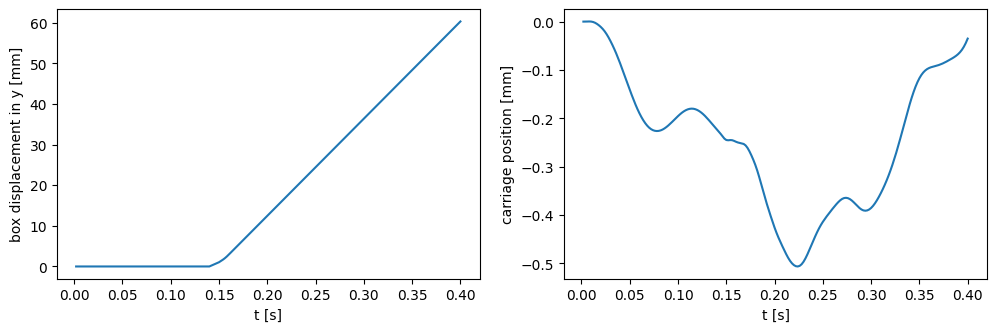

In [7]:
simulator = Simulator(diagram)
plant_context = plant.GetMyMutableContextFromRoot(simulator.get_mutable_context())
plant.SetFreeBodyPose(plant_context, box, RigidTransform([0.07, 0.075, 0.125]))
times, box_y, carriage_y = np.arange(1, 201) * robot.dt, [], []
for t in times:
    simulator.AdvanceTo(t - robot.dt / 2)
    box_y.append(plant.GetFreeBodyPose(plant_context, box).translation()[1])
    carriage_y.append(slider.get_translation(plant_context))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.plot(times, (np.array(box_y) - box_y[0]) * 1e3)
ax1.set_xlabel("t [s]")
ax1.set_ylabel("box displacement in y [mm]")
ax2.plot(times, np.array(carriage_y) * 1e3)
ax2.set_xlabel("t [s]")
ax2.set_ylabel("carriage position [mm]")
plt.show()

The tip reaches the box after about 0.14 s and pushes it away; after the contact the box moves on with constant velocity. The carriage moves by less than 1 mm in −y. It takes the reaction of the accelerated tubes from the start, and the reaction of the contact from 0.14 s. The contact is a stiff penalty contact without friction (`contact_stiffness`, default 10⁶ N/m²).

## Robot in the actuation unit
For this part you need the STL files of the [irp_concentric_tube_continuum_robot](https://github.com/IRP-TU-BS/irp_concentric_tube_continuum_robot) repository. Set `STL_DIR` to its `Models/stl_files` directory. Meshcat cannot show STL files, so pyctr writes OBJ copies to a cache directory once; the repository itself is not changed.

In [8]:
STL_DIR = os.environ.get("PYCTR_ACTUATION_UNIT_STL", "../../../irp_concentric_tube_continuum_robot/Models/stl_files")
print("STL files found:", os.path.isdir(STL_DIR))

STL files found: True


Two calls add the unit:

- `add_actuation_unit` registers the parts that do not move as visual geometry of a plant body (here the world). It returns the pose of the tube hole, which becomes the base plate of the robot.
- `ActuationUnitCarriages` draws the carriages, tube shafts and gears and the tubes inside the unit. It reads the same `betas` and `alphas` as the robot.

The tubes are clamped in the front carriages. The carriage of tube i is at d_i + L_i β_i behind the tube hole. d_i is the tube length inside the unit at β = 0 (`transmission_lengths`); by default the carriages start packed at the front. If a `betas` trajectory moves a carriage out of its travel (31 mm to 280 mm) or closer than 50 mm to its neighbour, the system raises an error. It does not limit the motion silently.

In [9]:
from pyctr.actuation_unit import ActuationUnitCarriages, add_actuation_unit

robot = load_continous_ctcr_model(CONFIG, DynamicConcentricTubeRobot, dt=2e-3)
builder = DiagramBuilder()
plant, scene_graph = AddMultibodyPlantSceneGraph(builder, time_step=robot.dt)
X_WExit = add_actuation_unit(plant, STL_DIR, moving_parts=True)
plant.Finalize()

robot.p_init, robot.R_init = X_WExit.translation().reshape(3, 1), X_WExit.rotation().matrix()  # base plate in the hole
robot.init_static()
ctr = builder.AddSystem(ConcentricTubeRobotSystem(robot, scene_graph))
unit = builder.AddSystem(ActuationUnitCarriages(scene_graph, STL_DIR, robot))
builder.Connect(ctr.GetOutputPort("geometry_pose"), scene_graph.get_source_pose_port(ctr.source_id))
builder.Connect(unit.GetOutputPort("geometry_pose"), scene_graph.get_source_pose_port(unit.source_id))

Both tubes are retracted (β to 0.3 and 0.2), the outer tube turns by 90°, and both tubes come out again. The same sources feed the robot and the carriages.

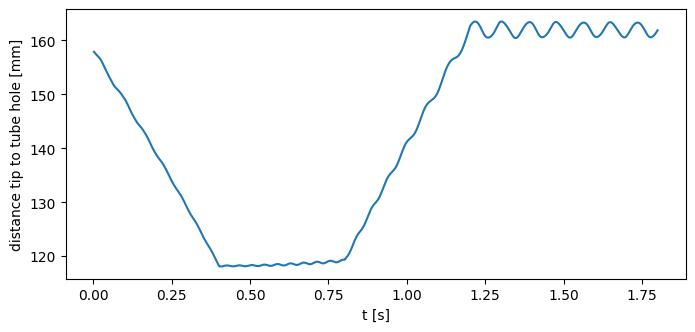

In [10]:
t = [0, 0.4, 0.8, 1.2, 1.6]
betas = builder.AddSystem(TrajectorySource(PiecewisePolynomial.FirstOrderHold(t, [[0, 0.3, 0.3, 0, 0], [0, 0.2, 0.2, 0, 0]])))
alphas = builder.AddSystem(TrajectorySource(PiecewisePolynomial.FirstOrderHold(t, [[0] * 5, [0, 0, np.pi / 2, np.pi / 2, np.pi / 2]])))
for source, port in ((betas, "betas"), (alphas, "alphas")):
    builder.Connect(source.get_output_port(), ctr.GetInputPort(port))
    builder.Connect(source.get_output_port(), unit.GetInputPort(port))
meshcat.Delete()
MeshcatVisualizer.AddToBuilder(builder, scene_graph, meshcat)
diagram = builder.Build()

times, tips, simulator = simulate(diagram, ctr, 1.8, robot.dt)
plt.figure(figsize=(8, 3.5))
plt.plot(times, np.linalg.norm(tips - X_WExit.translation(), axis=1) * 1e3)
plt.xlabel("t [s]")
plt.ylabel("distance tip to tube hole [mm]")
plt.show()

While the tubes are retracted (0 s to 0.4 s), the tip comes closer to the tube hole; when they come out again (0.8 s to 1.2 s), it moves away. The final distance is larger than at the start because the outer tube is now turned by 90°. The model computes a new grid for every change of `betas`, with the same number of nodes, and keeps the history of the time discretization by interpolation.

To mount the unit on a moving body, for example the flange of a robot arm, pass that body and its pose: `add_actuation_unit(plant, STL_DIR, body, X_BodyUnit, moving_parts=True)`, `ActuationUnitCarriages(scene_graph, STL_DIR, robot, plant, body, X_BodyUnit)` and `ConcentricTubeRobotSystem(robot, scene_graph, plant, body, X_BodyBase=X_BodyExit)`. Then connect `plant.get_body_poses_output_port()` to the `body_poses` input of the carriages as well.

## Limits
- The robot and the plant exchange forces with a delay of one time step. Use the same time step for both.
- The insertion model neglects the axial velocity of the tubes (as Till et al. 2020). Slow insertion gives the static shapes; fast insertion is only approximate.
- Contact has no friction, and each interval between two nodes uses only the closest obstacle. Contact begins within a step only if the obstacle was closer than `contact_margin` (5 mm) at the start of the step.
- The actuation unit is drawn only. Its motors and guide rails are boxes, the collets and the gears on the square shafts are missing.
- One simulated second of the example robot (186 nodes, 2 ms) takes about 6 s with the C++ class and about 2 minutes with the Python class.